In [15]:
# EXAMPLE


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [3]:
print("--- Part 1: K-Means Clustering ---")
X, y = make_blobs(n_samples=500, centers=3, cluster_std=0.60, random_state=42)
df_kmeans = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])
print("\nOriginal K-Means Dataset Head:")
print(df_kmeans.head())

--- Part 1: K-Means Clustering ---

Original K-Means Dataset Head:
   Feature_1  Feature_2
0  -6.190063  -7.302015
1   3.021747   1.940593
2   5.953761   1.488191
3  -2.744463   8.136177
4   5.360607   1.728324


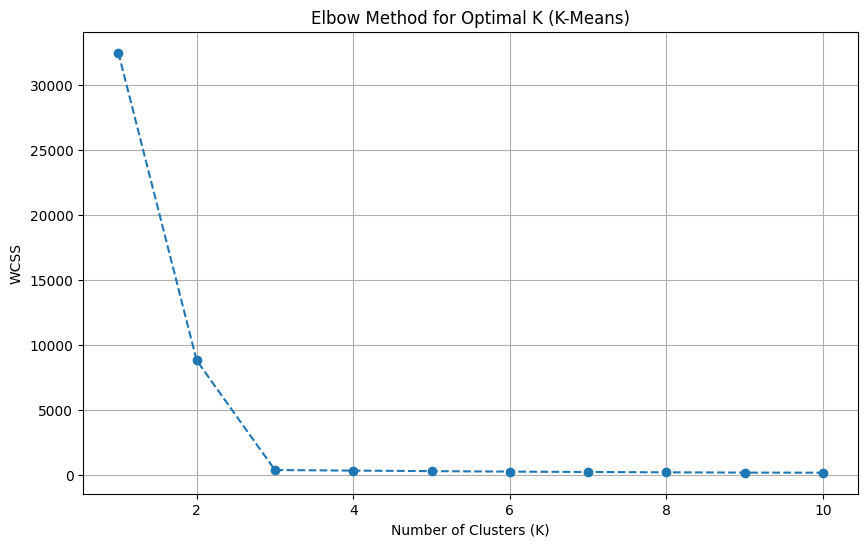

In [4]:
wcss = []
for i in range(1, 11):
 kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10,
random_state=42)
 kmeans.fit(X)
 wcss.append(kmeans.inertia_)
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K (K-Means)')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.grid(True)
plt.show()

In [5]:
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', max_iter=300, n_init=10,
random_state=42)
clusters = kmeans.fit_predict(X)
df_kmeans['Cluster'] = clusters

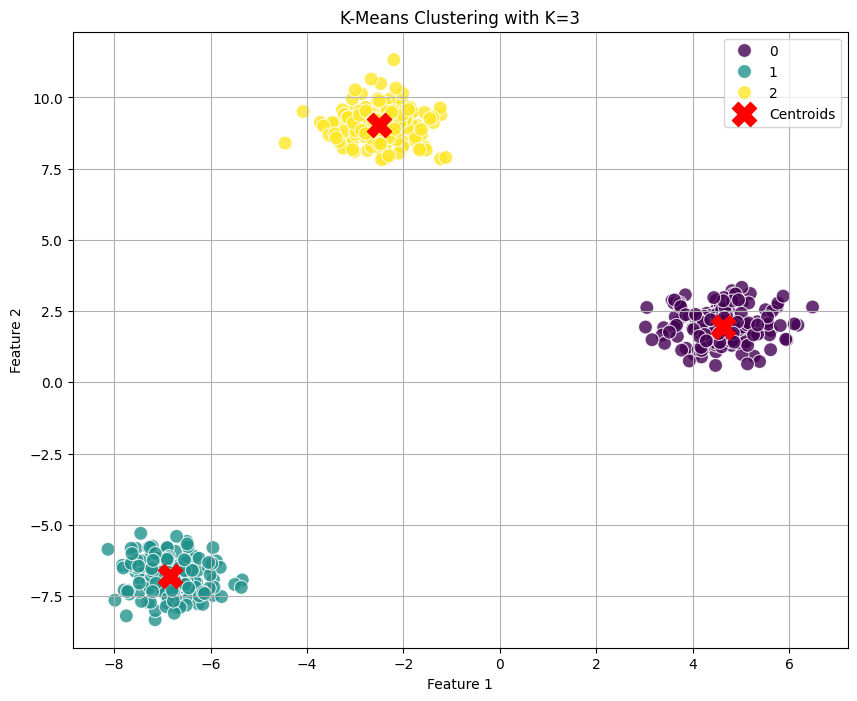

In [6]:
plt.figure(figsize=(10, 8))
sns.scatterplot(x='Feature_1', y='Feature_2', hue='Cluster', data=df_kmeans, palette='viridis',
s=100, alpha=0.8)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=300, c='red',
marker='X', label='Centroids')
plt.title(f'K-Means Clustering with K={optimal_k}')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)
plt.show()

In [7]:
silhouette_avg = silhouette_score(X, clusters)
print(f"\nSilhouette Score for K-Means (K={optimal_k}): {silhouette_avg:.3f}")


Silhouette Score for K-Means (K=3): 0.906


In [8]:
print("\n--- Part 2: Dimensionality Reduction with PCA ---")

X_pca, y_pca = make_blobs(n_samples=800, n_features=4, centers=4, cluster_std=1.0,
random_state=25)
df_pca_original = pd.DataFrame(X_pca, columns=[f'Feature_{i+1}' for i in
range(X_pca.shape[1])])
df_pca_original['True_Cluster'] = y_pca
print("\nOriginal PCA Dataset Head:")
print(df_pca_original.head())
print(f"Original PCA Dataset Shape: {df_pca_original.shape}")


--- Part 2: Dimensionality Reduction with PCA ---

Original PCA Dataset Head:
   Feature_1  Feature_2  Feature_3  Feature_4  True_Cluster
0  -2.403207  -7.363578   3.987749  -2.620445             1
1   1.724630  -3.153093  -2.695774  -7.519160             2
2   7.196781   1.152565  -3.300139  -6.363618             0
3  -0.124180  -8.947670   3.132549  -0.770765             1
4   0.363617  -1.008747  -1.669486  -6.463374             2
Original PCA Dataset Shape: (800, 5)


In [9]:
scaler = StandardScaler()
X_pca_scaled = scaler.fit_transform(X_pca)

In [10]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_pca_scaled)
df_principal_components = pd.DataFrame(principal_components,
columns=['Principal_Component_1', 'Principal_Component_2'])
df_principal_components['True_Cluster'] = y_pca
explained_variance = pca.explained_variance_ratio_
print("\nPrincipal Components Head:")
print(df_principal_components.head())
print(f"\nExplained Variance Ratio: {explained_variance}")
print(f"Total Explained Variance by 2 PCs: {explained_variance.sum():.3f}")


Principal Components Head:
   Principal_Component_1  Principal_Component_2  True_Cluster
0              -2.308426              -0.479026             1
1               0.192856              -0.856575             2
2               1.569925              -0.836109             0
3              -2.275925              -0.395180             1
4               0.104836              -0.433491             2

Explained Variance Ratio: [0.58174933 0.3266843 ]
Total Explained Variance by 2 PCs: 0.908


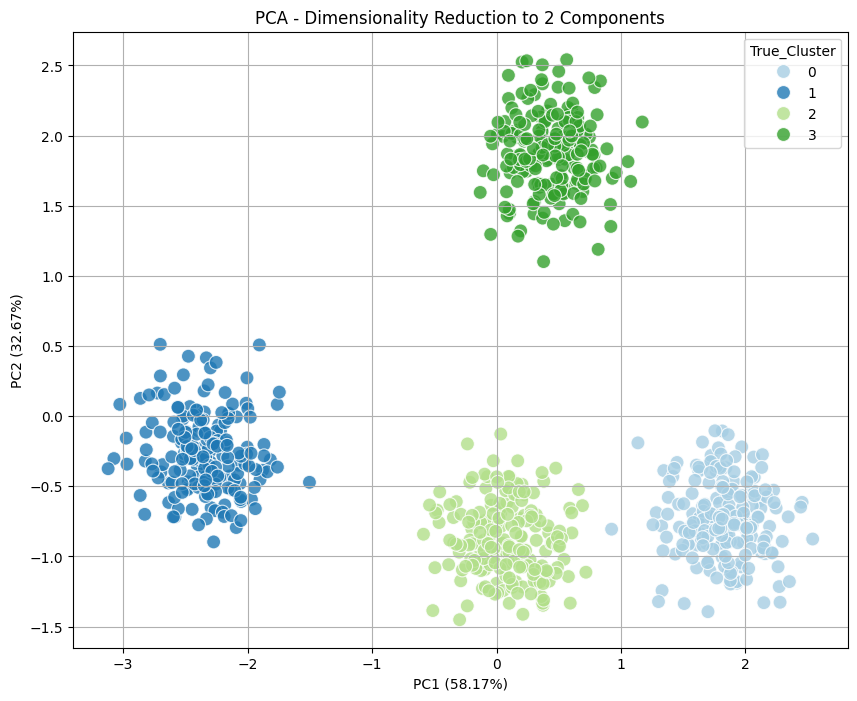

In [11]:
plt.figure(figsize=(10, 8))
sns.scatterplot(x='Principal_Component_1', y='Principal_Component_2', hue='True_Cluster',
data=df_principal_components, palette='Paired', s=100, alpha=0.8)
plt.title('PCA - Dimensionality Reduction to 2 Components')
plt.xlabel(f'PC1 ({explained_variance[0]*100:.2f}%)')
plt.ylabel(f'PC2 ({explained_variance[1]*100:.2f}%)')
plt.grid(True)
plt.show()

In [12]:
kmeans_pca = KMeans(n_clusters=4, init='k-means++', max_iter=300, n_init=10,
random_state=42)
clusters_pca = kmeans_pca.fit_predict(principal_components)
df_principal_components['KMeans_Cluster_on_PCA'] = clusters_pca

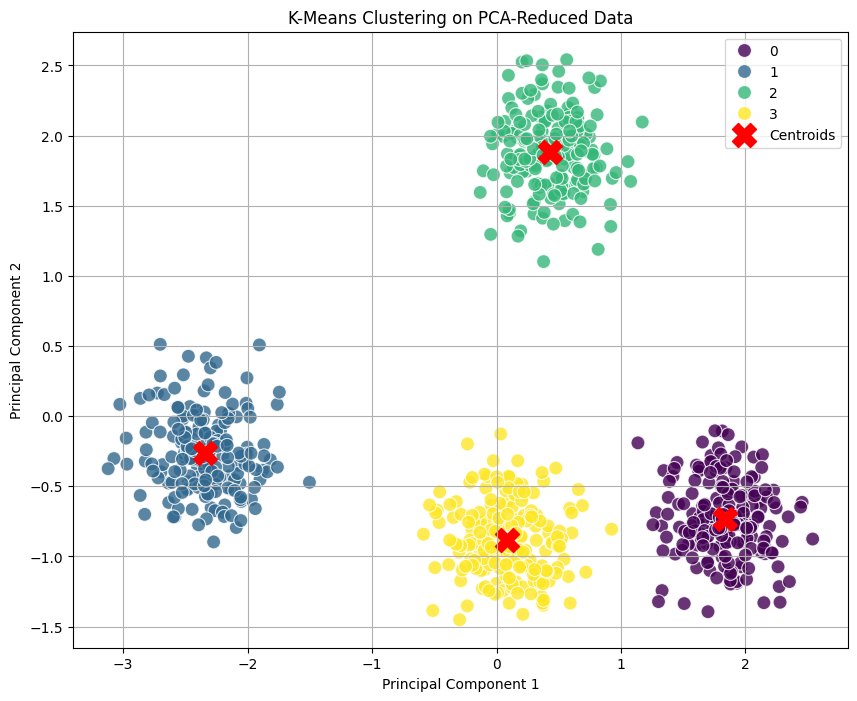

In [13]:
plt.figure(figsize=(10, 8))
sns.scatterplot(x='Principal_Component_1', y='Principal_Component_2',
hue='KMeans_Cluster_on_PCA',
data=df_principal_components, palette='viridis', s=100, alpha=0.8)
plt.scatter(kmeans_pca.cluster_centers_[:, 0], kmeans_pca.cluster_centers_[:, 1], s=300,
c='red', marker='X', label='Centroids')
plt.title('K-Means Clustering on PCA-Reduced Data')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True)
plt.show()

In [14]:
silhouette_avg_pca = silhouette_score(principal_components, clusters_pca)
print(f"\nSilhouette Score for K-Means on PCA-Reduced Data (K=4):{silhouette_avg_pca:.3f}")


Silhouette Score for K-Means on PCA-Reduced Data (K=4):0.776
